In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Active CPU")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
!pip install -q torch torchvision torchaudio
!pip install -q scikit-learn matplotlib seaborn tqdm pandas

In [4]:
import torch
import torchvision

import torchvision.transforms as transforms
from torchvision import datasets

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU disponible:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU disponible: True


In [5]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 340kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.16MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.8MB/s]

Training samples: 60000
Testing samples: 10000


In [6]:
print(torch.cuda.get_device_name(0))

Tesla T4


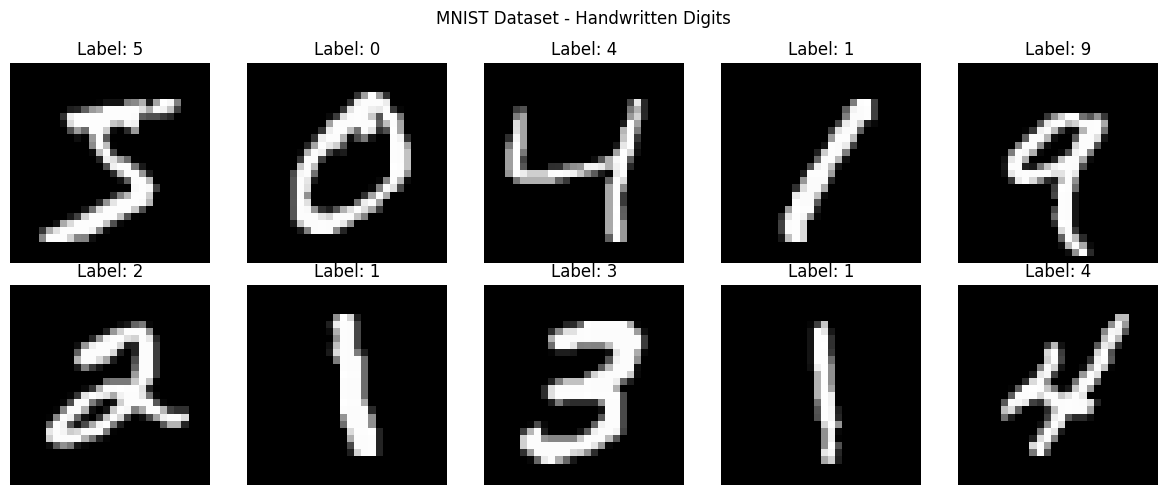

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")

    ax.set_title(f"Label: {label}")

    ax.axis("off")

plt.suptitle("MNIST Dataset - Handwritten Digits")
plt.tight_layout()
plt.show()

In [8]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 469
Testing batches: 79


In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Image dimensions:", images[0].shape)
print("First label:", labels[0].item())

Images shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
Image dimensions: torch.Size([1, 28, 28])
First label: 8


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [12]:
class CNN(nn.Module):

    def __init__(self, num_classes=10):

        super(CNN, self).__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            stride=1,
            padding=1
        )

        # Second convolutional layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1
        )

        # Max pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Dropout regularization
        self.dropout = nn.Dropout(0.25)

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)

        self.fc2 = nn.Linear(128, num_classes)


    def forward(self, x):

        # First convolution + ReLU + Pooling
        x = F.relu(self.conv1(x))
        x = self.pool(x)

        # Second convolution + ReLU + Pooling
        x = F.relu(self.conv2(x))
        x = self.pool(x)

        # Dropout
        x = self.dropout(x)

        # Flatten
        x = torch.flatten(x, 1)

        # Fully connected
        x = F.relu(self.fc1(x))

        # Output
        x = self.fc2(x)

        return x

In [13]:
cnn_model = CNN(num_classes=10)

cnn_model = cnn_model.to(device)

print(cnn_model)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [14]:
# Get one batch
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Forward propagation
outputs = cnn_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])


In [15]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Number of epochs
EPOCHS = 5

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Epochs: 5


In [16]:
import time
from tqdm.auto import tqdm

train_losses = []
train_accuracies = []

start_time = time.time()

for epoch in range(EPOCHS):

    cnn_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(train_loader)

    for images, labels in progress_bar:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = cnn_model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress_bar.set_postfix(loss=loss.item())

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Training Loss: {epoch_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy*100:.2f}%")

training_time = time.time() - start_time

print("\nTotal Training Time:", round(training_time, 2), "seconds")

  0%|          | 0/469 [00:00<?, ?it/s]


Epoch [1/5]
Training Loss: 0.2413
Training Accuracy: 92.77%


  0%|          | 0/469 [00:00<?, ?it/s]


Epoch [2/5]
Training Loss: 0.0660
Training Accuracy: 97.97%


  0%|          | 0/469 [00:00<?, ?it/s]


Epoch [3/5]
Training Loss: 0.0460
Training Accuracy: 98.56%


  0%|          | 0/469 [00:00<?, ?it/s]


Epoch [4/5]
Training Loss: 0.0377
Training Accuracy: 98.80%


  0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e54e4349d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e54e4349d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch [5/5]
Training Loss: 0.0322
Training Accuracy: 98.97%

Total Training Time: 60.28 seconds


In [17]:
import os

os.makedirs("models", exist_ok=True)

torch.save(
    cnn_model.state_dict(),
    "models/cnn_mnist.pth"
)

print("CNN model saved successfully!")

CNN model saved successfully!


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

cnn_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = cnn_model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Prediction completed!")

Prediction completed!


In [19]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("CNN Evaluation Results")
print("----------------------")
print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")

CNN Evaluation Results
----------------------
Accuracy : 98.93%
Precision: 98.94%
Recall   : 98.93%
F1-score : 98.93%


In [20]:
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9869    0.9980    0.9924       980
           1     0.9912    0.9974    0.9943      1135
           2     0.9961    0.9816    0.9888      1032
           3     0.9796    0.9970    0.9882      1010
           4     0.9888    0.9929    0.9909       982
           5     0.9866    0.9888    0.9877       892
           6     0.9937    0.9875    0.9906       958
           7     0.9836    0.9942    0.9889      1028
           8     0.9979    0.9702    0.9839       974
           9     0.9890    0.9841    0.9866      1009

    accuracy                         0.9893     10000
   macro avg     0.9893    0.9892    0.9892     10000
weighted avg     0.9894    0.9893    0.9893     10000



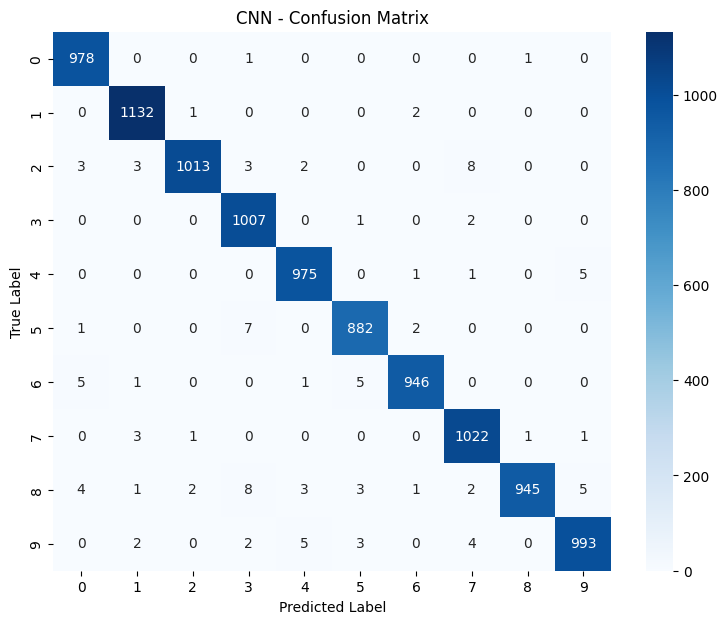

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

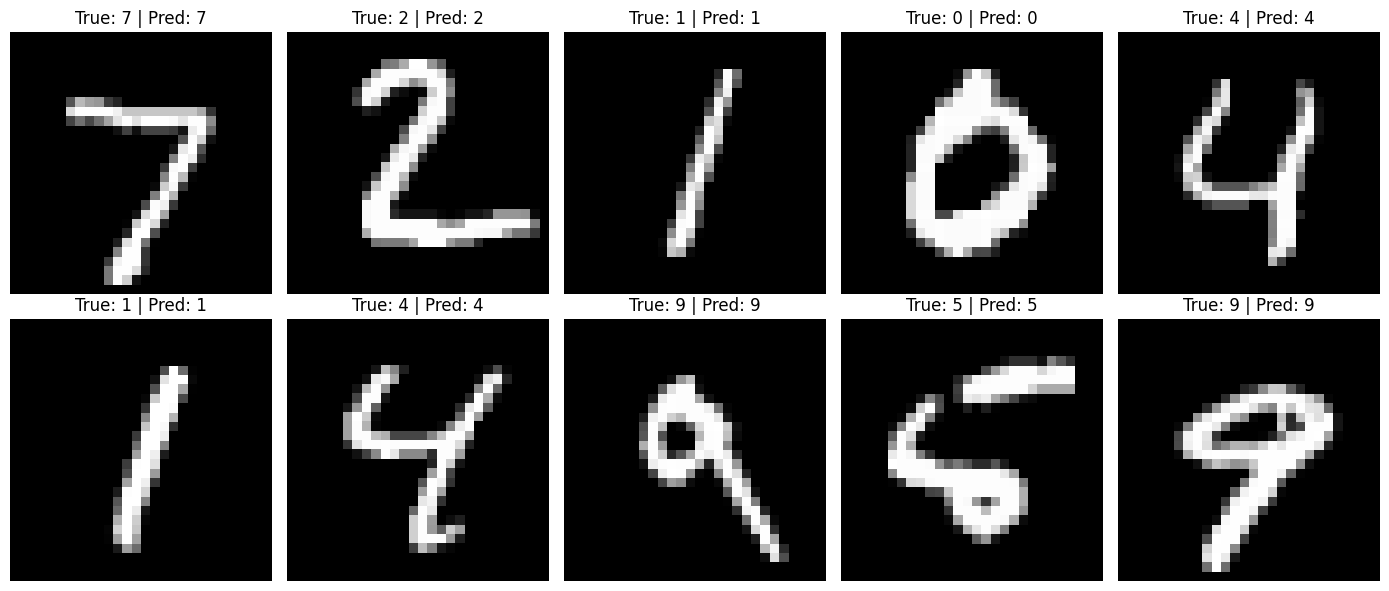

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):

    image = test_dataset[i][0]
    true_label = test_dataset[i][1]

    with torch.no_grad():

        output = cnn_model(
            image.unsqueeze(0).to(device)
        )

        predicted_label = output.argmax(1).item()

    ax.imshow(image.squeeze(), cmap="gray")

    ax.set_title(
        f"True: {true_label} | Pred: {predicted_label}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
cnn_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

print(cnn_metrics)

torch.save(
    cnn_model.state_dict(),
    "cnn_mnist.pth"
)

{'Accuracy': 0.9893, 'Precision': 0.9893616134847103, 'Recall': 0.9893, 'F1-score': 0.9892895789152774}


In [24]:
from torch.utils.data import Dataset, DataLoader, Subset

class MNISTDetection(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, label = self.dataset[idx]

        # Convert grayscale to RGB
        image = image.repeat(3, 1, 1)

        # Bounding box covering the entire image
        target = {
            "boxes": torch.tensor(
                [[0.0, 0.0, 28.0, 28.0]],
                dtype=torch.float32
            ),

            # 0 is reserved for background
            "labels": torch.tensor(
                [label + 1],
                dtype=torch.int64
            ),

            "image_id": torch.tensor([idx])
        }

        return image, target


def detection_collate(batch):
    return tuple(zip(*batch))


print("MNIST Detection Dataset created!")

MNIST Detection Dataset created!


In [25]:
train_detection_dataset = MNISTDetection(train_dataset)
test_detection_dataset = MNISTDetection(test_dataset)

train_det_subset = Subset(
    train_detection_dataset,
    range(12000)
)

test_det_subset = Subset(
    test_detection_dataset,
    range(2000)
)

train_det_loader = DataLoader(
    train_det_subset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    collate_fn=detection_collate
)

test_det_loader = DataLoader(
    test_det_subset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate
)

print("Training images:", len(train_det_subset))
print("Testing images:", len(test_det_subset))

Training images: 12000
Testing images: 2000


In [26]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.rpn import AnchorGenerator

anchor_generator = AnchorGenerator(
    sizes=(
        (8,),
        (12,),
        (16,),
        (24,),
        (32,)
    ),
    aspect_ratios=(
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0),
        (0.5, 1.0, 2.0)
    )
)

faster_model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=11,
    min_size=28,
    max_size=28,
    rpn_anchor_generator=anchor_generator
)

faster_model = faster_model.to(device)

print("Faster R-CNN created successfully!")

Faster R-CNN created successfully!


In [27]:
images, targets = next(iter(train_det_loader))

print("Image shape:", images[0].shape)
print("Bounding box:", targets[0]["boxes"])
print("Label:", targets[0]["labels"])

Image shape: torch.Size([3, 28, 28])
Bounding box: tensor([[ 0.,  0., 28., 28.]])
Label: tensor([8])


In [28]:
import torch.optim as optim
import time
from tqdm.auto import tqdm

optimizer_faster = optim.SGD(
    [p for p in faster_model.parameters()
     if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

EPOCHS_FASTER = 3

print("Optimizer:", optimizer_faster)
print("Epochs:", EPOCHS_FASTER)

Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.005
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0.0005
)
Epochs: 3


In [29]:
faster_losses = []

start_time_faster = time.time()

for epoch in range(EPOCHS_FASTER):

    faster_model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        train_det_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS_FASTER}"
    )

    for images, targets in progress_bar:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]

        optimizer_faster.zero_grad()

        loss_dict = faster_model(images, targets)

        loss = sum(loss for loss in loss_dict.values())

        loss.backward()

        optimizer_faster.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = total_loss / len(train_det_loader)

    faster_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_FASTER}] "
        f"Loss: {epoch_loss:.4f}"
    )

faster_training_time = time.time() - start_time_faster

print(
    "Training Time:",
    round(faster_training_time, 2),
    "seconds"
)

Epoch 1/3:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch [1/3] Loss: 0.1004


Epoch 2/3:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch [2/3] Loss: 0.0337


Epoch 3/3:   0%|          | 0/750 [00:00<?, ?it/s]

Epoch [3/3] Loss: 0.0184
Training Time: 558.19 seconds


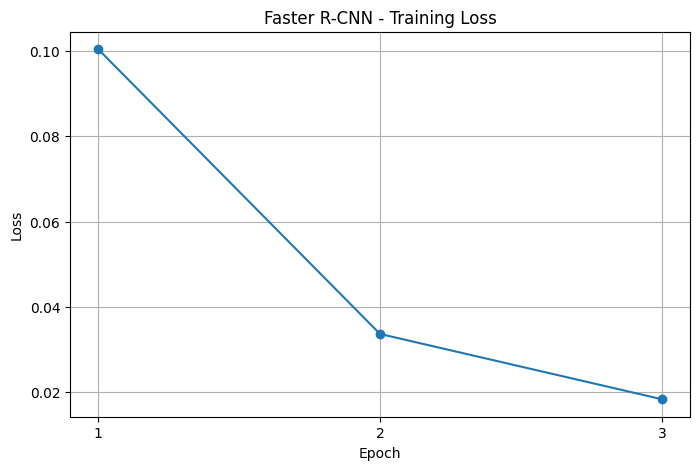

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS_FASTER + 1),
    faster_losses,
    marker="o"
)

plt.title("Faster R-CNN - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, EPOCHS_FASTER + 1))
plt.grid()

plt.show()

In [31]:
torch.save(
    faster_model.state_dict(),
    "faster_rcnn_mnist.pth"
)

print("Faster R-CNN saved successfully!")


Faster R-CNN saved successfully!


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

faster_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, targets in test_det_loader:

        images = [img.to(device) for img in images]
        outputs = faster_model(images)

        for output, target in zip(outputs, targets):

            # Classe réelle : retirer 1 car 0 est réservé au background
            true_label = target["labels"].item() - 1

            # Prédiction ayant le score le plus élevé
            if len(output["scores"]) > 0:
                best_idx = output["scores"].argmax().item()
                predicted_label = output["labels"][best_idx].item() - 1
            else:
                predicted_label = 0

            y_true.append(true_label)
            y_pred.append(predicted_label)

# Calcul des métriques
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("Faster R-CNN Evaluation Results")
print("--------------------------------")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-score  : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Faster R-CNN Evaluation Results
--------------------------------
Accuracy  : 90.30%
Precision : 90.45%
Recall    : 90.30%
F1-score  : 90.24%

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       175
           1       0.95      0.99      0.97       234
           2       0.91      0.90      0.91       219
           3       0.92      0.90      0.91       207
           4       0.93      0.92      0.93       217
           5       0.89      0.92      0.91       179
           6       0.91      0.92      0.92       178
           7       0.79      0.90      0.84       205
           8       0.93      0.77      0.84       192
           9       0.88      0.81      0.84       194

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

cnn_model.eval()

y_true_cnn = []
y_pred_cnn = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true_cnn.extend(labels.cpu().numpy())
        y_pred_cnn.extend(predictions.cpu().numpy())

        # On s'arrête après les 2000 premières images
        if len(y_true_cnn) >= 2000:
            y_true_cnn = y_true_cnn[:2000]
            y_pred_cnn = y_pred_cnn[:2000]
            break

# Calcul des métriques
cnn_accuracy = accuracy_score(y_true_cnn, y_pred_cnn)
cnn_precision = precision_score(
    y_true_cnn, y_pred_cnn, average="weighted", zero_division=0
)
cnn_recall = recall_score(
    y_true_cnn, y_pred_cnn, average="weighted", zero_division=0
)
cnn_f1 = f1_score(
    y_true_cnn, y_pred_cnn, average="weighted", zero_division=0
)

print("CNN Evaluation Results (2000 images)")
print("------------------------------------")
print(f"Accuracy  : {cnn_accuracy * 100:.2f}%")
print(f"Precision : {cnn_precision * 100:.2f}%")
print(f"Recall    : {cnn_recall * 100:.2f}%")
print(f"F1-score  : {cnn_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_cnn, y_pred_cnn, zero_division=0
))

CNN Evaluation Results (2000 images)
------------------------------------
Accuracy  : 98.40%
Precision : 98.41%
Recall    : 98.40%
F1-score  : 98.40%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       175
           1       0.98      1.00      0.99       234
           2       0.99      0.97      0.98       219
           3       0.98      1.00      0.99       207
           4       0.99      0.99      0.99       217
           5       0.98      0.99      0.99       179
           6       0.98      0.98      0.98       178
           7       0.97      0.98      0.97       205
           8       1.00      0.96      0.98       192
           9       0.98      0.98      0.98       194

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms

from torchvision.models import vgg16, VGG16_Weights
from torchvision import datasets
from torch.utils.data import DataLoader

# Transformations pour VGG16
vgg_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Charger MNIST avec les nouvelles transformations
vgg_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=vgg_transform
)

vgg_test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=vgg_transform
)

# DataLoaders
vgg_train_loader = DataLoader(
    vgg_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

vgg_test_loader = DataLoader(
    vgg_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("VGG16 datasets prepared successfully!")
print("Training images:", len(vgg_train_dataset))
print("Testing images:", len(vgg_test_dataset))

images, labels = next(iter(vgg_train_loader))
print("Image shape:", images.shape)

VGG16 datasets prepared successfully!
Training images: 60000
Testing images: 10000
Image shape: torch.Size([32, 3, 224, 224])


In [35]:
# Charger VGG16 pré-entraîné
vgg_model = vgg16(weights=VGG16_Weights.DEFAULT)

# Geler toutes les couches
for param in vgg_model.parameters():
    param.requires_grad = False

# Remplacer la dernière couche
vgg_model.classifier[6] = nn.Linear(
    vgg_model.classifier[6].in_features,
    10
)

# Envoyer le modèle sur GPU
vgg_model = vgg_model.to(device)

# Fonction de perte et optimiseur
criterion_vgg = nn.CrossEntropyLoss()

optimizer_vgg = optim.Adam(
    vgg_model.classifier[6].parameters(),
    lr=0.001
)

print("VGG16 model loaded successfully!")
print("Number of classes:", vgg_model.classifier[6].out_features)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:09<00:00, 58.0MB/s]


VGG16 model loaded successfully!
Number of classes: 10


In [36]:
import time
from tqdm import tqdm

num_epochs = 3
vgg_losses = []

start_time = time.time()

for epoch in range(num_epochs):

    vgg_model.train()
    running_loss = 0.0

    progress_bar = tqdm(vgg_train_loader)

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_vgg.zero_grad()

        outputs = vgg_model(images)
        loss = criterion_vgg(outputs, labels)

        loss.backward()
        optimizer_vgg.step()

        running_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(vgg_train_loader)
    vgg_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {epoch_loss:.4f}")

training_time_vgg = time.time() - start_time

print(f"VGG16 Training Time: {training_time_vgg:.2f} seconds")

100%|██████████| 1875/1875 [06:45<00:00,  4.63it/s, loss=0.489]


Epoch [1/3] Loss: 0.5241


100%|██████████| 1875/1875 [07:03<00:00,  4.43it/s, loss=0.518]


Epoch [2/3] Loss: 0.4332


100%|██████████| 1875/1875 [07:04<00:00,  4.42it/s, loss=0.405]

Epoch [3/3] Loss: 0.4246
VGG16 Training Time: 1252.64 seconds


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

vgg_model.eval()

y_true_vgg = []
y_pred_vgg = []

with torch.no_grad():
    for images, labels in vgg_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = vgg_model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true_vgg.extend(labels.cpu().numpy())
        y_pred_vgg.extend(predictions.cpu().numpy())

# Calcul des métriques
vgg_accuracy = accuracy_score(y_true_vgg, y_pred_vgg)
vgg_precision = precision_score(
    y_true_vgg, y_pred_vgg, average="weighted", zero_division=0
)
vgg_recall = recall_score(
    y_true_vgg, y_pred_vgg, average="weighted", zero_division=0
)
vgg_f1 = f1_score(
    y_true_vgg, y_pred_vgg, average="weighted", zero_division=0
)

print("VGG16 Evaluation Results")
print("------------------------")
print(f"Accuracy  : {vgg_accuracy * 100:.2f}%")
print(f"Precision : {vgg_precision * 100:.2f}%")
print(f"Recall    : {vgg_recall * 100:.2f}%")
print(f"F1-score  : {vgg_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_vgg, y_pred_vgg, zero_division=0
))

VGG16 Evaluation Results
------------------------
Accuracy  : 94.41%
Precision : 94.56%
Recall    : 94.41%
F1-score  : 94.42%

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       980
           1       0.99      0.98      0.99      1135
           2       0.97      0.90      0.94      1032
           3       0.95      0.90      0.92      1010
           4       0.94      0.97      0.95       982
           5       0.86      0.95      0.90       892
           6       0.94      0.97      0.96       958
           7       0.94      0.94      0.94      1028
           8       0.98      0.92      0.95       974
           9       0.94      0.92      0.93      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.95      0.94      0.94     10000



In [38]:
from torchvision.models import alexnet, AlexNet_Weights

alex_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

alex_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=alex_transform
)

alex_test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=alex_transform
)

alex_train_loader = DataLoader(
    alex_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

alex_test_loader = DataLoader(
    alex_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("AlexNet datasets prepared successfully!")
print("Training images:", len(alex_train_dataset))
print("Testing images:", len(alex_test_dataset))

images, labels = next(iter(alex_train_loader))
print("Image shape:", images.shape)

AlexNet datasets prepared successfully!
Training images: 60000
Testing images: 10000
Image shape: torch.Size([32, 3, 224, 224])


In [39]:
# Charger AlexNet avec les poids pré-entraînés
alex_model = alexnet(weights=AlexNet_Weights.DEFAULT)

# Geler toutes les couches
for param in alex_model.parameters():
    param.requires_grad = False

# Remplacer la dernière couche par 10 classes
alex_model.classifier[6] = nn.Linear(
    alex_model.classifier[6].in_features,
    10
)

# Envoyer le modèle sur GPU
alex_model = alex_model.to(device)

# Fonction de perte
criterion_alex = nn.CrossEntropyLoss()

# Optimiseur : entraîner uniquement la dernière couche
optimizer_alex = optim.Adam(
    alex_model.classifier[6].parameters(),
    lr=0.001
)

print("AlexNet model loaded successfully!")
print("Number of classes:", alex_model.classifier[6].out_features)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 169MB/s]


AlexNet model loaded successfully!
Number of classes: 10


In [40]:
import time
from tqdm import tqdm

num_epochs = 3
alex_losses = []

start_time = time.time()

for epoch in range(num_epochs):

    alex_model.train()
    running_loss = 0.0

    progress_bar = tqdm(alex_train_loader)

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_alex.zero_grad()

        outputs = alex_model(images)
        loss = criterion_alex(outputs, labels)

        loss.backward()
        optimizer_alex.step()

        running_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(alex_train_loader)
    alex_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {epoch_loss:.4f}")

training_time_alex = time.time() - start_time

print(f"AlexNet Training Time: {training_time_alex:.2f} seconds")

100%|██████████| 1875/1875 [02:33<00:00, 12.25it/s, loss=0.137]


Epoch [1/3] Loss: 0.4220


100%|██████████| 1875/1875 [02:32<00:00, 12.33it/s, loss=0.236]


Epoch [2/3] Loss: 0.3434


100%|██████████| 1875/1875 [02:31<00:00, 12.37it/s, loss=0.204]

Epoch [3/3] Loss: 0.3333
AlexNet Training Time: 456.72 seconds


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

alex_model.eval()

y_true_alex = []
y_pred_alex = []

with torch.no_grad():
    for images, labels in alex_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = alex_model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true_alex.extend(labels.cpu().numpy())
        y_pred_alex.extend(predictions.cpu().numpy())

# Calcul des métriques
alex_accuracy = accuracy_score(y_true_alex, y_pred_alex)

alex_precision = precision_score(
    y_true_alex, y_pred_alex,
    average="weighted", zero_division=0
)

alex_recall = recall_score(
    y_true_alex, y_pred_alex,
    average="weighted", zero_division=0
)

alex_f1 = f1_score(
    y_true_alex, y_pred_alex,
    average="weighted", zero_division=0
)

print("AlexNet Evaluation Results")
print("--------------------------")
print(f"Accuracy  : {alex_accuracy * 100:.2f}%")
print(f"Precision : {alex_precision * 100:.2f}%")
print(f"Recall    : {alex_recall * 100:.2f}%")
print(f"F1-score  : {alex_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_alex, y_pred_alex,
    zero_division=0
))

AlexNet Evaluation Results
--------------------------
Accuracy  : 93.90%
Precision : 94.30%
Recall    : 93.90%
F1-score  : 93.89%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.83      0.90      1032
           3       0.83      0.97      0.89      1010
           4       1.00      0.92      0.96       982
           5       0.92      0.88      0.90       892
           6       0.93      0.97      0.95       958
           7       0.90      0.99      0.94      1028
           8       0.99      0.88      0.93       974
           9       0.92      0.98      0.95      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_first_2000(model, loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

            if len(y_true) >= 2000:
                break

    y_true = y_true[:2000]
    y_pred = y_pred[:2000]

    return {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(y_true, y_pred, average="weighted") * 100,
        "Recall": recall_score(y_true, y_pred, average="weighted") * 100,
        "F1-score": f1_score(y_true, y_pred, average="weighted") * 100
    }

vgg_2000 = evaluate_first_2000(vgg_model, vgg_test_loader, device)
alex_2000 = evaluate_first_2000(alex_model, alex_test_loader, device)

print("VGG16 - 2000 images:", vgg_2000)
print("AlexNet - 2000 images:", alex_2000)

VGG16 - 2000 images: {'Accuracy': 93.85, 'Precision': 94.05506672056909, 'Recall': 93.85, 'F1-score': 93.86097594049677}
AlexNet - 2000 images: {'Accuracy': 92.75, 'Precision': 93.25778784227953, 'Recall': 92.75, 'F1-score': 92.74971191213577}


In [43]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Normalisation des images MNIST
vit_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Chargement des données
vit_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=vit_transform
)

vit_test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=vit_transform
)

# DataLoaders
vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

vit_test_loader = DataLoader(
    vit_test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Taille des données d'entraînement :", len(vit_train_dataset))
print("Taille des données de test :", len(vit_test_dataset))

# Vérification de la forme des images
images, labels = next(iter(vit_train_loader))

print("Forme d'un batch :", images.shape)
print("Forme d'une image :", images[0].shape)

Taille des données d'entraînement : 60000
Taille des données de test : 10000
Forme d'un batch : torch.Size([128, 1, 28, 28])
Forme d'une image : torch.Size([1, 28, 28])


In [44]:
# Paramètres des patches
img_size = 28
patch_size = 7

num_patches = (img_size // patch_size) ** 2
patch_dim = patch_size * patch_size

print("Taille de l'image :", img_size, "x", img_size)
print("Taille d'un patch :", patch_size, "x", patch_size)
print("Nombre de patches :", num_patches)
print("Nombre de pixels par patch :", patch_dim)

# Découpage d'une image en patches
image = images[0]  # Première image du batch

patches = image.unfold(1, patch_size, patch_size)\
               .unfold(2, patch_size, patch_size)

# Transformation en une séquence de vecteurs
patches = patches.contiguous().view(1, num_patches, patch_dim)

print("Forme des patches :", patches.shape)

Taille de l'image : 28 x 28
Taille d'un patch : 7 x 7
Nombre de patches : 16
Nombre de pixels par patch : 49
Forme des patches : torch.Size([1, 16, 49])


In [45]:
# Dimension des vecteurs d'embedding
embed_dim = 64

# Couche de projection des patches
patch_embedding = nn.Linear(patch_dim, embed_dim).to(device)

# Transformation des patches en embeddings
embedded_patches = patch_embedding(patches.to(device))

print("Forme avant embedding :", patches.shape)
print("Forme après embedding :", embedded_patches.shape)

Forme avant embedding : torch.Size([1, 16, 49])
Forme après embedding : torch.Size([1, 16, 64])


In [46]:
# Token de classification
cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

# Embeddings de position : 16 patches + 1 CLS Token
pos_embedding = nn.Parameter(
    torch.zeros(1, num_patches + 1, embed_dim)
)

# Ajouter le CLS Token au début de la séquence
cls_tokens = cls_token.expand(1, -1, -1).to(device)

tokens = torch.cat(
    (cls_tokens, embedded_patches),
    dim=1
)

# Ajouter les informations de position
tokens = tokens + pos_embedding.to(device)

print("Forme après ajout du CLS Token :",
      torch.cat((cls_tokens, embedded_patches), dim=1).shape)

print("Forme finale après Positional Embedding :", tokens.shape)

Forme après ajout du CLS Token : torch.Size([1, 17, 64])
Forme finale après Positional Embedding : torch.Size([1, 17, 64])


In [47]:
# Paramètres du Transformer
num_heads = 4
num_layers = 4
mlp_dim = 128

# Une couche Transformer Encoder
encoder_layer = nn.TransformerEncoderLayer(
    d_model=embed_dim,
    nhead=num_heads,
    dim_feedforward=mlp_dim,
    dropout=0.1,
    batch_first=True
)

# Empilement de 4 couches Transformer
transformer_encoder = nn.TransformerEncoder(
    encoder_layer,
    num_layers=num_layers
).to(device)

# Tester le Transformer avec nos tokens
encoded_tokens = transformer_encoder(tokens)

print("Forme avant Transformer :", tokens.shape)
print("Forme après Transformer :", encoded_tokens.shape)

Forme avant Transformer : torch.Size([1, 17, 64])
Forme après Transformer : torch.Size([1, 17, 64])


In [48]:
# Couche de normalisation
norm = nn.LayerNorm(embed_dim).to(device)

# Couche de classification : 10 classes (chiffres 0 à 9)
classifier = nn.Linear(embed_dim, 10).to(device)

# Récupérer le CLS Token après le Transformer
cls_output = encoded_tokens[:, 0]

# Normalisation
cls_output = norm(cls_output)

# Classification
output = classifier(cls_output)

print("Forme du CLS Token :", cls_output.shape)
print("Forme de la sortie :", output.shape)
print("Nombre de classes :", output.shape[1])

Forme du CLS Token : torch.Size([1, 64])
Forme de la sortie : torch.Size([1, 10])
Nombre de classes : 10


In [49]:
class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=28,
        patch_size=7,
        in_channels=1,
        num_classes=10,
        embed_dim=64,
        num_heads=4,
        num_layers=4,
        mlp_dim=128
    ):
        super().__init__()

        self.num_patches = (img_size // patch_size) ** 2
        patch_dim = in_channels * patch_size * patch_size

        # Découpage et projection des patches
        self.patch_embedding = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # CLS Token et Positional Embedding
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, embed_dim)
        )

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Classification
        self.norm = nn.LayerNorm(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # 1. Patch Embedding
        x = self.patch_embedding(x)

        # 2. Transformer la grille en séquence
        x = x.flatten(2).transpose(1, 2)

        # 3. Ajouter le CLS Token
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        # 4. Ajouter les positions
        x = x + self.pos_embedding

        # 5. Transformer Encoder
        x = self.transformer(x)

        # 6. Classification avec le CLS Token
        x = self.norm(x[:, 0])
        x = self.classifier(x)

        return x


# Créer le modèle
vit_model = VisionTransformer().to(device)

# Tester le modèle
sample_images, sample_labels = next(iter(vit_train_loader))
sample_images = sample_images.to(device)

sample_output = vit_model(sample_images)

print(vit_model)
print("Forme des images :", sample_images.shape)
print("Forme de la sortie :", sample_output.shape)
print("Nombre de paramètres :", sum(p.numel() for p in vit_model.parameters()))

VisionTransformer(
  (patch_embedding): Conv2d(1, 64, kernel_size=(7, 7), stride=(7, 7))
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=64, out_features=10, bias=True)
)
Forme des images : torch.Size([128, 1, 28, 28])
Forme de la sortie : torch.S

In [50]:
# Fonction de perte
criterion = nn.CrossEntropyLoss()

# Optimiseur
optimizer = torch.optim.Adam(
    vit_model.parameters(),
    lr=0.001
)

# Nombre d'époques
num_epochs = 10

# Liste pour conserver les pertes
vit_losses = []

# Temps de début
start_time = time.time()

for epoch in range(num_epochs):

    vit_model.train()
    running_loss = 0.0

    for images, labels in vit_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Réinitialiser les gradients
        optimizer.zero_grad()

        # Prédiction
        outputs = vit_model(images)

        # Calcul de la perte
        loss = criterion(outputs, labels)

        # Rétropropagation
        loss.backward()

        # Mise à jour des poids
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(vit_train_loader)
    vit_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

# Temps total
vit_training_time = time.time() - start_time

print("\nTemps total d'entraînement :", round(vit_training_time, 2), "secondes")

Epoch [1/10], Loss: 0.7760
Epoch [2/10], Loss: 0.2565
Epoch [3/10], Loss: 0.1669
Epoch [4/10], Loss: 0.1309
Epoch [5/10], Loss: 0.1134
Epoch [6/10], Loss: 0.1013
Epoch [7/10], Loss: 0.0893
Epoch [8/10], Loss: 0.0840
Epoch [9/10], Loss: 0.0775
Epoch [10/10], Loss: 0.0751

Temps total d'entraînement : 196.77 secondes


In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

vit_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in vit_test_loader:

        images = images.to(device)

        outputs = vit_model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

        # Garder uniquement les 2000 premières images
        if len(all_labels) >= 2000:
            break

# Limiter exactement à 2000 images
all_predictions = all_predictions[:2000]
all_labels = all_labels[:2000]

# Calcul des métriques
vit_accuracy = accuracy_score(all_labels, all_predictions)
vit_precision = precision_score(
    all_labels, all_predictions, average="weighted"
)
vit_recall = recall_score(
    all_labels, all_predictions, average="weighted"
)
vit_f1 = f1_score(
    all_labels, all_predictions, average="weighted"
)

print("Résultats du Vision Transformer (ViT)")
print("--------------------------------------")
print(f"Accuracy  : {vit_accuracy * 100:.2f}%")
print(f"Precision : {vit_precision * 100:.2f}%")
print(f"Recall    : {vit_recall * 100:.2f}%")
print(f"F1-score  : {vit_f1 * 100:.2f}%")
print("Images testées :", len(all_labels))


Résultats du Vision Transformer (ViT)
--------------------------------------
Accuracy  : 96.90%
Precision : 96.92%
Recall    : 96.90%
F1-score  : 96.89%
Images testées : 2000


In [52]:
import pandas as pd

results = {
    "Model": [
        "CNN",
        "Faster R-CNN",
        "VGG16",
        "AlexNet",
        "ViT"
    ],

    "Accuracy (%)": [
        98.40, 90.30, 93.85, 92.75, 96.90
    ],

    "Precision (%)": [
        98.41, 90.45, 94.06, 93.26, 96.92
    ],

    "Recall (%)": [
        98.40, 90.30, 93.85, 92.75, 96.90
    ],

    "F1-score (%)": [
        98.40, 90.24, 93.86, 92.75, 96.89
    ],

    "Training Time (s)": [
        60.28, 558.19, 1252.64, 456.72, 196.77
    ]
}

df_results = pd.DataFrame(results)

display(df_results)

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Training Time (s)
0,CNN,98.40,98.41,98.40,98.40,60.28
1,Faster R-CNN,90.30,90.45,90.30,90.24,558.19
2,VGG16,93.85,94.06,93.85,93.86,1252.64
3,AlexNet,92.75,93.26,92.75,92.75,456.72
4,ViT,96.90,96.92,96.90,96.89,196.77


In [53]:
import pandas as pd

results = {
    "Model": [
        "CNN",
        "Faster R-CNN",
        "VGG16",
        "AlexNet",
        "ViT"
    ],

    "Accuracy (%)": [
        98.40, 90.30, 93.85, 92.75, 96.90
    ],

    "Precision (%)": [
        98.41, 90.45, 94.06, 93.26, 96.92
    ],

    "Recall (%)": [
        98.40, 90.30, 93.85, 92.75, 96.90
    ],

    "F1-score (%)": [
        98.40, 90.24, 93.86, 92.75, 96.89
    ],

    "Loss": [
        0.0322, 0.0184, 0.4246, 0.3333, 0.0751
    ],

    "Training Time (s)": [
        60.28, 558.19, 1252.64, 456.72, 196.77
    ]
}

df_results = pd.DataFrame(results)

display(df_results)


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Loss,Training Time (s)
0,CNN,98.40,98.41,98.40,98.40,0.0322,60.28
1,Faster R-CNN,90.30,90.45,90.30,90.24,0.0184,558.19
2,VGG16,93.85,94.06,93.85,93.86,0.4246,1252.64
3,AlexNet,92.75,93.26,92.75,92.75,0.3333,456.72
4,ViT,96.90,96.92,96.90,96.89,0.0751,196.77


In [54]:
display(df_results.style.hide(axis="index"))


Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Loss,Training Time (s)
CNN,98.400000,98.410000,98.400000,98.400000,0.032200,60.280000
Faster R-CNN,90.300000,90.450000,90.300000,90.240000,0.018400,558.190000
VGG16,93.850000,94.060000,93.850000,93.860000,0.424600,1252.640000
AlexNet,92.750000,93.260000,92.750000,92.750000,0.333300,456.720000
ViT,96.900000,96.920000,96.900000,96.890000,0.075100,196.770000
